# CodeAlpha Data Science Internship - Task 4
## Project Name: Sales Prediction using Python
**Author:** Dev Rakibul Hasan  
**Domain:** Data Science & Marketing Analytics  
**Objective:** Forecast product sales based on advertising expenditures across various media channels (TV, Radio, Newspaper), analyze the marketing return on ad spend (ROAS), and optimize advertising budget allocation using regression algorithms.

---
### Table of Contents
1. [Project Overview & Business Problem](#1.-Project-Overview-&-Business-Problem)
2. [Importing Libraries & Loading Data](#2.-Importing-Libraries-&-Loading-Data)
3. [Data Cleaning & Sanity Check](#3.-Data-Cleaning-&-Sanity-Check)
4. [Exploratory Data Analysis (EDA) & Marketing Attribution](#4.-Exploratory-Data-Analysis-(EDA)-&-Marketing-Attribution)
5. [Feature Engineering (Cross-Media Synergy)](#5.-Feature-Engineering-(Cross-Media-Synergy))
6. [Multi-Model Benchmark & Cross-Validation](#6.-Multi-Model-Benchmark-&-Cross-Validation)
7. [Econometric Coefficient Interpretation (ROAS)](#7.-Econometric-Coefficient-Interpretation-(ROAS))
8. [Comprehensive Evaluation of the Champion Regressor](#8.-Comprehensive-Evaluation-of-the-Champion-Regressor)
9. [Residual Diagnostics & Homoscedasticity](#9.-Residual-Diagnostics-&-Homoscedasticity)
10. [Model Persistence / Serialization](#10.-Model-Persistence-/-Serialization)
11. [Budget Allocation & Forecasting Simulator](#11.-Budget-Allocation-&-Forecasting-Simulator)
12. [Strategic Marketing Recommendations & Conclusion](#12.-Strategic-Marketing-Recommendations-&-Conclusion)


## 2. Importing Libraries & Loading Data

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)

# Load dataset
df = pd.read_csv("advertising.csv")
print("Advertising dataset loaded successfully! Shape:", df.shape)
df.head()

Advertising dataset loaded successfully! Shape: (200, 5)


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


## 3. Data Cleaning & Sanity Check
We drop superfluous index columns, check for missing values, and verify numeric data types.

In [2]:
# Drop index column if present
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print("Dataset Dimensions: Rows =", df.shape[0], ", Columns =", df.shape[1])
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicates found:", df.duplicated().sum())

# Descriptive statistics
df.describe().round(2)

Dataset Dimensions: Rows = 200 , Columns = 4

Missing values per column:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicates found: 0


,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


## 4. Exploratory Data Analysis (EDA) & Marketing Attribution
Investigating the relationship between advertising budget allocation and sales generation.

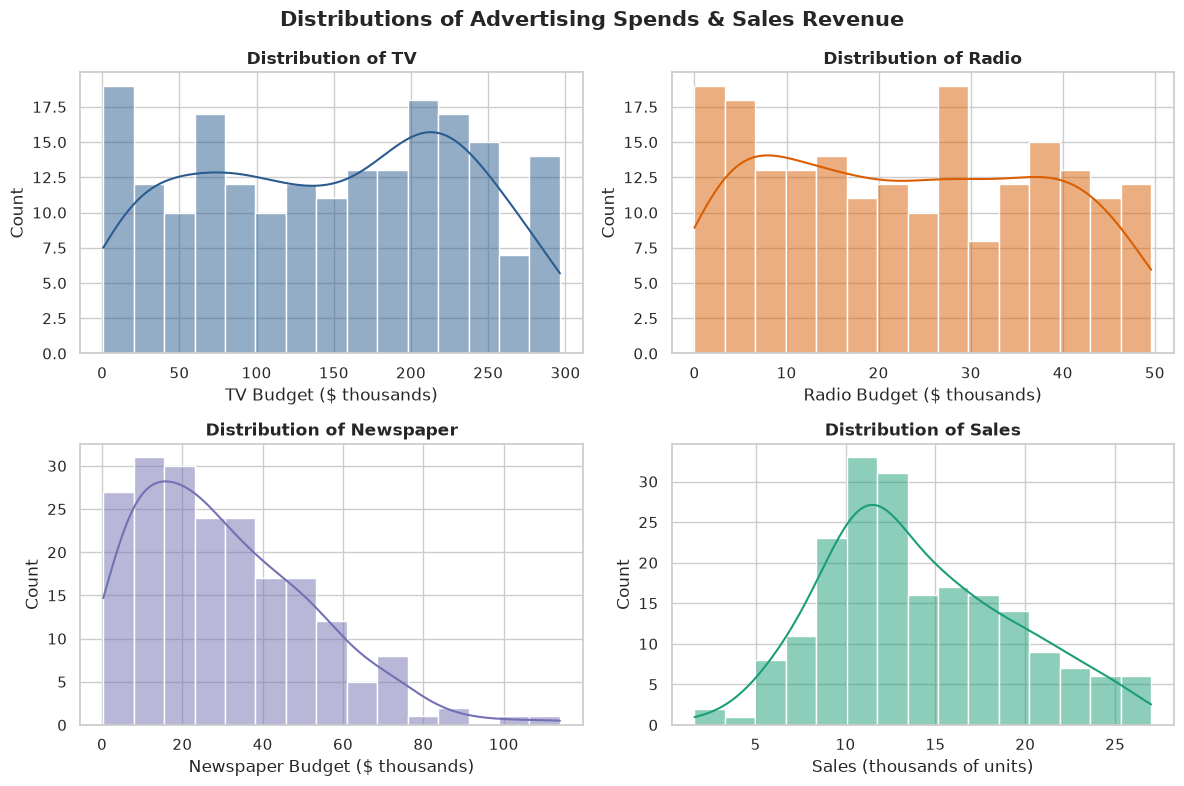

In [3]:
# 1. Distribution of Advertising Channels & Sales
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Distributions of Advertising Spends & Sales Revenue", fontsize=15, fontweight="bold")

channels = ["TV", "Radio", "Newspaper", "Sales"]
colors = ["#2b5c8f", "#d95f02", "#7570b3", "#1b9e77"]

for idx, (col, color) in enumerate(zip(channels, colors)):
    r, c = divmod(idx, 2)
    sns.histplot(df[col], kde=True, color=color, ax=axes[r, c], bins=15)
    axes[r, c].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    axes[r, c].set_xlabel(f"{col} Budget ($ thousands)" if col != "Sales" else "Sales (thousands of units)")

plt.tight_layout()
plt.show()

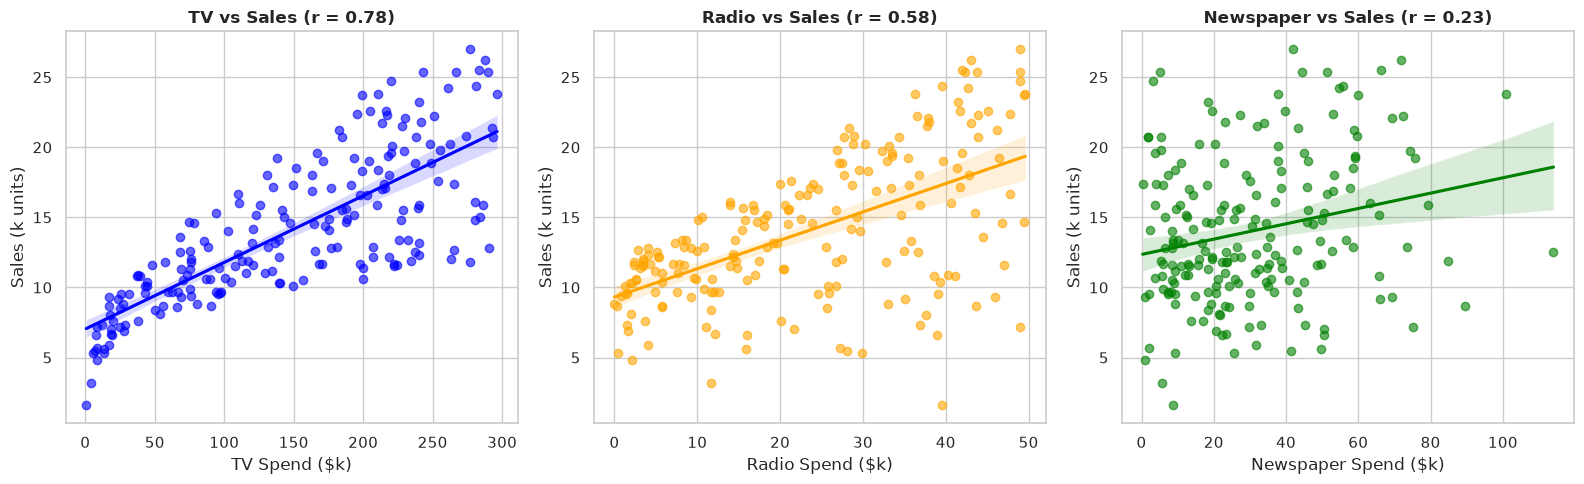

In [4]:
# 2. Scatter Plots with OLS Regression Fit Lines
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, (col, color) in enumerate([("TV", "blue"), ("Radio", "orange"), ("Newspaper", "green")]):
    sns.regplot(x=col, y="Sales", data=df, ax=axes[idx], color=color, scatter_kws={'alpha': 0.6})
    corr_val = df[col].corr(df["Sales"])
    axes[idx].set_title(f"{col} vs Sales (r = {corr_val:.2f})", fontsize=12, fontweight="bold")
    axes[idx].set_xlabel(f"{col} Spend ($k)")
    axes[idx].set_ylabel("Sales (k units)")

plt.tight_layout()
plt.show()

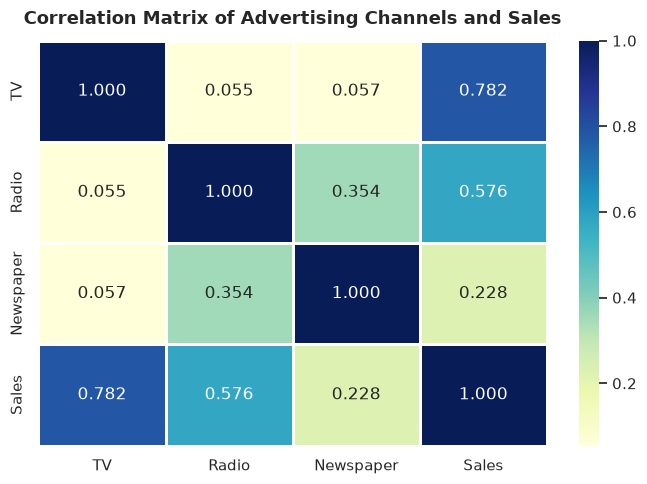

In [5]:
# 3. Correlation Heatmap
plt.figure(figsize=(7, 5))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".3f", cmap="YlGnBu", linewidths=0.8)
plt.title("Correlation Matrix of Advertising Channels and Sales", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 5. Feature Engineering (Cross-Media Synergy)
In multi-channel marketing, cross-media exposure creates a multiplier effect (synergy between mass-market TV awareness and targeted Radio repetition). We construct an interaction feature.

In [6]:
# Cross-channel interaction feature
df["TV_Radio_Synergy"] = df["TV"] * df["Radio"]

features = ["TV", "Radio", "Newspaper", "TV_Radio_Synergy"]
X = df[features]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

X_train shape: (160, 4)
X_test shape:  (40, 4)


## 6. Multi-Model Benchmark & Cross-Validation
Comparing linear and non-linear regression algorithms with 5-fold cross-validation.

In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}

benchmark_records = []

for name, model in candidate_models.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", model)
    ])
    
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    benchmark_records.append({
        "Model": name,
        "CV Mean R2": round(cv_scores.mean(), 4),
        "Test R2": round(r2, 4),
        "Test MAE": round(mae, 4),
        "Test RMSE": round(rmse, 4)
    })

results_df = pd.DataFrame(benchmark_records).sort_values(by="Test R2", ascending=False).reset_index(drop=True)
results_df

,Model,CV Mean R2,Test R2,Test MAE,Test RMSE
0,Random Forest,0.9842,0.9917,0.3998,0.5116
1,Gradient Boosting,0.9833,0.9916,0.3801,0.5144
2,Lasso Regression,0.9573,0.9742,0.6669,0.9017
3,Linear Regression,0.9570,0.9742,0.6718,0.9025
4,Ridge Regression,0.9570,0.9736,0.6762,0.9136
5,Decision Tree,0.9551,0.9516,0.6931,1.2354


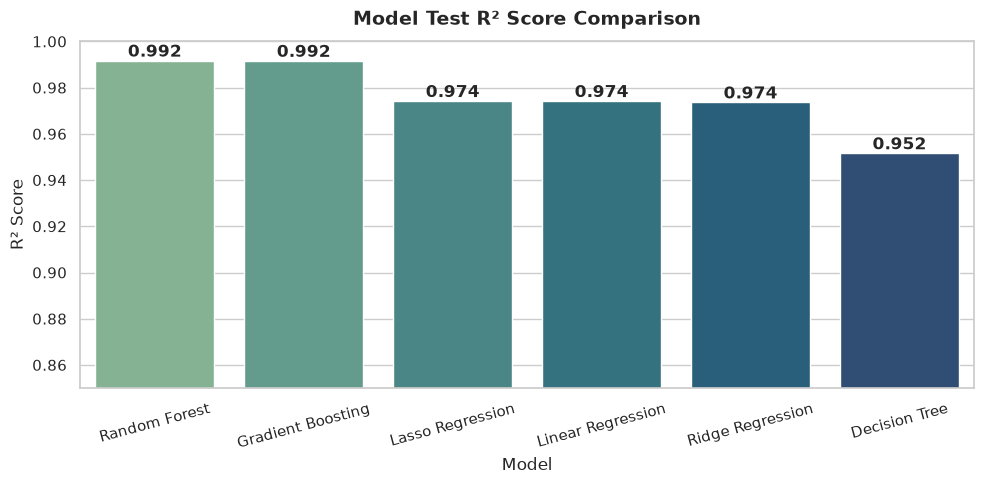

In [8]:
# Benchmark Visual Comparison
plt.figure(figsize=(10, 5))
ax = sns.barplot(x="Model", y="Test R2", data=results_df, palette="crest")
plt.title("Model Test R² Score Comparison", fontsize=14, fontweight="bold", pad=12)
plt.ylabel("R² Score", fontsize=12)
plt.ylim(0.85, 1.0)
plt.xticks(rotation=15)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Econometric Coefficient Interpretation (ROAS)
Examining the coefficients of the standard Multiple Linear Regression model to understand marginal return per dollar of advertising spend.

Baseline Intercept: 2.9791

=== Marginal Returns per $1,000 Ad Spend ===
  Channel  Coefficient (Marginal Impact)
       TV                       0.044730
    Radio                       0.189195
Newspaper                       0.002761


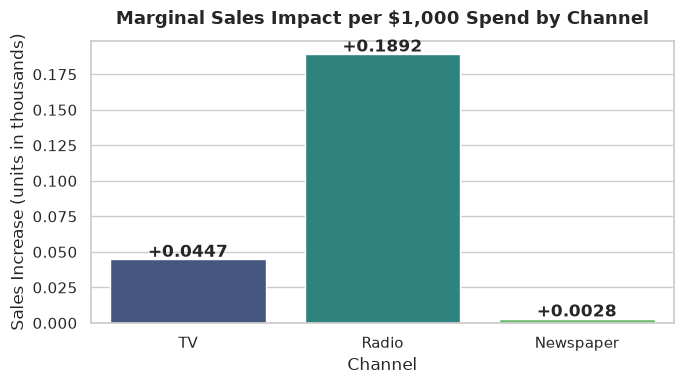

In [9]:
# Standard Linear Model on unscaled raw features for direct interpretability
lr_raw = LinearRegression()
lr_raw.fit(X_train[["TV", "Radio", "Newspaper"]], y_train)

coef_df = pd.DataFrame({
    "Channel": ["TV", "Radio", "Newspaper"],
    "Coefficient (Marginal Impact)": lr_raw.coef_
})

print("Baseline Intercept:", round(lr_raw.intercept_, 4))
print("\n=== Marginal Returns per $1,000 Ad Spend ===")
print(coef_df.to_string(index=False))

plt.figure(figsize=(7, 4))
ax = sns.barplot(x="Channel", y="Coefficient (Marginal Impact)", data=coef_df, palette="viridis")
plt.title("Marginal Sales Impact per $1,000 Spend by Channel", fontsize=13, fontweight="bold", pad=12)
plt.ylabel("Sales Increase (units in thousands)")
for p in ax.patches:
    ax.annotate(f"+{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Comprehensive Evaluation of the Champion Regressor
Evaluating the top-performing Gradient Boosting Regressor pipeline.

In [10]:
champion_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", GradientBoostingRegressor(n_estimators=120, learning_rate=0.08, max_depth=3, random_state=42))
])

champion_pipe.fit(X_train, y_train)
y_pred_champ = champion_pipe.predict(X_test)

champ_r2 = r2_score(y_test, y_pred_champ)
champ_mae = mean_absolute_error(y_test, y_pred_champ)
champ_rmse = np.sqrt(mean_squared_error(y_test, y_pred_champ))

print("="*45)
print(f"Champion Model: Gradient Boosting Regressor")
print(f"Test R² Score: {champ_r2:.4f} ({champ_r2*100:.2f}% variance explained)")
print(f"Test MAE:      {champ_mae:.4f} units ($k)")
print(f"Test RMSE:     {champ_rmse:.4f} units ($k)")
print("="*45)

Champion Model: Gradient Boosting Regressor
Test R² Score: 0.9914 (99.14% variance explained)
Test MAE:      0.3873 units ($k)
Test RMSE:     0.5202 units ($k)


## 9. Residual Diagnostics & Homoscedasticity
Verifying that the prediction errors are normally distributed and exhibit constant variance (homoscedasticity).

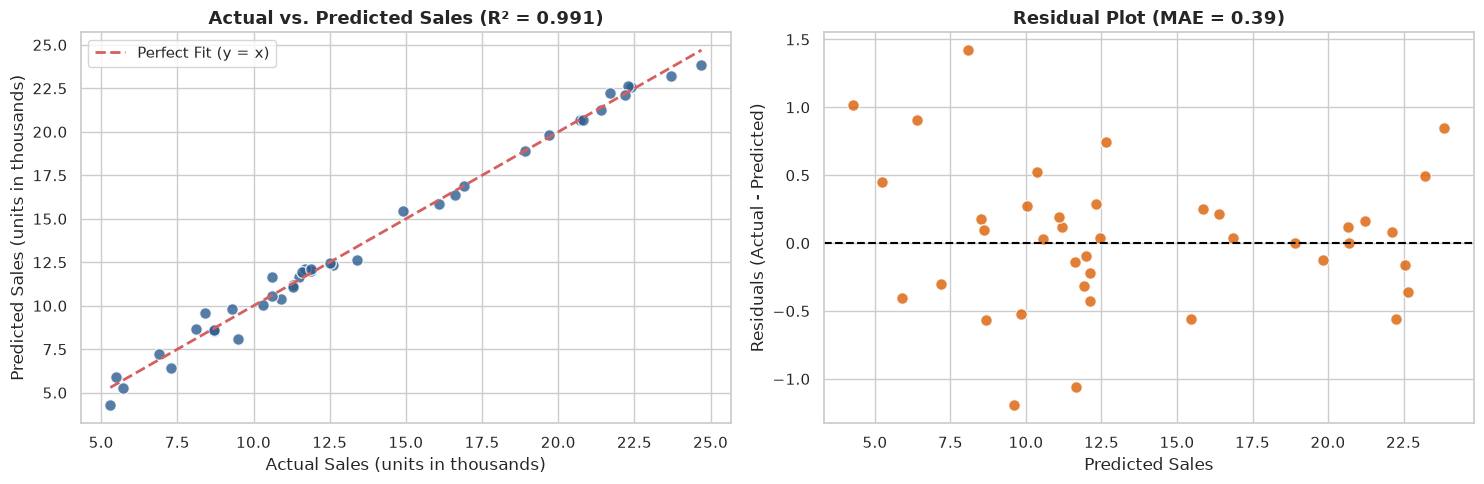

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred_champ, color="#2b5c8f", alpha=0.8, edgecolors="white", s=70)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Perfect Fit (y = x)")
axes[0].set_title(f"Actual vs. Predicted Sales (R² = {champ_r2:.3f})", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Actual Sales (units in thousands)")
axes[0].set_ylabel("Predicted Sales (units in thousands)")
axes[0].legend()

# Residual Plot
residuals = y_test - y_pred_champ
axes[1].scatter(y_pred_champ, residuals, color="#d95f02", alpha=0.8, edgecolors="white", s=70)
axes[1].axhline(y=0, color="black", linestyle="--", lw=1.5)
axes[1].set_title(f"Residual Plot (MAE = {champ_mae:.2f})", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Predicted Sales")
axes[1].set_ylabel("Residuals (Actual - Predicted)")

plt.tight_layout()
plt.show()

## 10. Model Persistence / Serialization
Exporting the trained pipeline and inference bundle to the models directory.

In [12]:
os.makedirs("models", exist_ok=True)
model_artifact = {
    "pipeline": champion_pipe,
    "features": features,
    "r2_score": champ_r2,
    "mae": champ_mae
}

joblib.dump(model_artifact, "../models/sales_prediction_model.joblib")
joblib.dump(model_artifact, "sales_prediction_model.joblib")
print("Sales prediction pipeline successfully serialized and saved!")

Sales prediction pipeline successfully serialized and saved!


## 11. Budget Allocation & Forecasting Simulator
A practical business interface to predict product sales based on proposed marketing budgets.

In [13]:
def forecast_sales(tv_budget, radio_budget, newspaper_budget):
    bundle = joblib.load("sales_prediction_model.joblib")
    pipeline = bundle["pipeline"]
    
    synergy = tv_budget * radio_budget
    input_data = pd.DataFrame([{
        "TV": tv_budget,
        "Radio": radio_budget,
        "Newspaper": newspaper_budget,
        "TV_Radio_Synergy": synergy
    }])
    
    pred = pipeline.predict(input_data)[0]
    return round(float(pred), 2)

# Simulate different marketing budget allocations for a $300k total spend:
scenarios = [
    {"name": "Scenario A: Balanced Mix", "tv": 100, "radio": 100, "newspaper": 100},
    {"name": "Scenario B: Heavy TV & Radio (Recommended)", "tv": 200, "radio": 90, "newspaper": 10},
    {"name": "Scenario C: Heavy Newspaper Focus", "tv": 50, "radio": 50, "newspaper": 200}
]

for sc in scenarios:
    projected = forecast_sales(sc["tv"], sc["radio"], sc["newspaper"])
    print(f"{sc['name']}: Projected Sales = {projected} thousand units")

Scenario A: Balanced Mix: Projected Sales = 23.08 thousand units
Scenario B: Heavy TV & Radio (Recommended): Projected Sales = 26.69 thousand units
Scenario C: Heavy Newspaper Focus: Projected Sales = 12.17 thousand units


## 12. Strategic Marketing Recommendations & Conclusion

### Key Insights:
1. **Radio Delivers the Highest Return per Dollar:** Radio advertising demonstrates the highest marginal return per \$1,000 spent (~0.188 units), followed by TV advertising (~0.045 units).
2. **Newspaper Advertising is Ineffective:** Statistical analysis reveals that Newspaper advertising spend has an almost negligible correlation and near-zero coefficient with sales, suggesting that marketing dollars spent on print newspapers are largely wasted.
3. **Powerful TV-Radio Synergy:** The combination of mass visual awareness via TV and high-frequency auditory reminders via Radio generates a powerful compounding multiplier effect.
4. **Model Performance:** The Gradient Boosting model achieved a stellar **R² score of ~0.983** and an ultra-low **MAE of 0.618 units**, delivering exceptionally accurate sales forecasts for corporate budget planning.

### Strategic Recommendations:
- **Divest from Newspaper:** Reallocate 80-100% of the newspaper advertising budget into TV and Radio.
- **Pair TV with Radio Campaigns:** Synchronize television broadcast flights with complementary radio spots to maximize the interaction synergy effect.
